# Problem 2 – Transformer from scratch
Student ID: 2026aj05405
Chosen width d = 128 (divisible by 4 heads)
Seeds: 42, 123, 456

In [33]:
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import accuracy_score, f1_score
import time
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import math
import os
import urllib.request
import zipfile
import gc
import pandas as pd
gc.collect()

def set_seed(seed):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

print('CUDA available:', torch.cuda.is_available())

CUDA available: False


## 1. Data pipelines

In [34]:
def ensure_har():
    if not os.path.exists("UCI HAR Dataset"):
        print("Downloading HAR dataset...")
        url = "https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip"
        urllib.request.urlretrieve(url, "har.zip")
        zipfile.ZipFile("har.zip").extractall(".")
        nested = "UCI HAR Dataset.zip"
        if os.path.exists(nested):
            zipfile.ZipFile(nested).extractall(".")
        print("Download complete.")
    return "UCI HAR Dataset"

base = ensure_har()

def load_signals(base_path, split):
    signal_path = os.path.join(base_path, split, "Inertial Signals")
    channels = [
        "body_acc_x", "body_acc_y", "body_acc_z",
        "body_gyro_x", "body_gyro_y", "body_gyro_z",
        "total_acc_x", "total_acc_y", "total_acc_z"
    ]
    signals = []
    for ch in channels:
        fname = os.path.join(signal_path, f"{ch}_{split}.txt")
        signals.append(np.loadtxt(fname))
    return np.stack(signals, axis=-1).astype(np.float32)

X_train = load_signals(base, "train")
X_test  = load_signals(base, "test")
y_train = np.loadtxt(os.path.join(base, "train", "y_train.txt")).astype(int)
y_test  = np.loadtxt(os.path.join(base, "test", "y_test.txt")).astype(int)
subject_train = np.loadtxt(os.path.join(base, "train", "subject_train.txt")).astype(int)

print("Train:", X_train.shape, "Test:", X_test.shape)

def subject_split(X, y, subjects, seed, n_val=4):
    rng = np.random.default_rng(seed)
    unique = np.unique(subjects)
    val_subjects = rng.choice(unique, n_val, replace=False)
    val_mask = np.isin(subjects, val_subjects)
    train_mask = ~val_mask
    return (X[train_mask], y[train_mask], subjects[train_mask],
            X[val_mask],   y[val_mask],   subjects[val_mask])

SEEDS = [42, 123, 456]
normalised = {}

for seed in SEEDS:
    X_tr, y_tr, sub_tr, X_val, y_val, sub_val = subject_split(
        X_train, y_train, subject_train, seed
    )
    overlap = set(sub_tr) & set(sub_val)
    print(f"Seed {seed}: train subjects={len(np.unique(sub_tr))}, "
          f"val subjects={len(np.unique(sub_val))}, overlap={overlap}")

    mean = X_tr.mean(axis=(0, 1), keepdims=True)
    std  = X_tr.std(axis=(0, 1), keepdims=True) + 1e-8

    normalised[seed] = {
        "X_tr":  (X_tr  - mean) / std,
        "y_tr":  y_tr,
        "X_val": (X_val - mean) / std,
        "y_val": y_val,
        "X_test": (X_test - mean) / std,
        "y_test": y_test,
        "mean": mean,
        "std": std
    }

print("normalised ready for seeds:", list(normalised.keys()))

Train: (7352, 128, 9) Test: (2947, 128, 9)
Seed 42: train subjects=17, val subjects=4, overlap=set()
Seed 123: train subjects=17, val subjects=4, overlap=set()
Seed 456: train subjects=17, val subjects=4, overlap=set()
normalised ready for seeds: [42, 123, 456]


## 1. Scaled dot-product attention from scratch

In [35]:
def scaled_dot_product_attention(Q, K, V, mask=None):
    """
    Q, K, V: (..., seq_len, d_k)
    mask: broadcastable boolean tensor, True = keep, False = mask out
    Returns: output, attention_weights
    """
    d_k = Q.size(-1)
    scores = torch.matmul(Q, K.transpose(-2, -1)) / math.sqrt(d_k)
    
    if mask is not None:
        scores = scores.masked_fill(~mask, -1e9)
    
    weights = F.softmax(scores, dim=-1)
    output = torch.matmul(weights, V)
    return output, weights


# ---------- Unit tests ----------
torch.manual_seed(0)
B, T, D = 2, 5, 8
Q = torch.randn(B, T, D)
K = torch.randn(B, T, D)
V = torch.randn(B, T, D)

# 1. Row sums = 1
out, w = scaled_dot_product_attention(Q, K, V)
assert torch.allclose(w.sum(dim=-1), torch.ones(B, T), atol=1e-5)

# 2. Matches PyTorch
out_pt = F.scaled_dot_product_attention(Q, K, V)
assert torch.allclose(out, out_pt, atol=1e-5)

# 3. Causal mask
causal = torch.tril(torch.ones(T, T, dtype=torch.bool))
out_c, w_c = scaled_dot_product_attention(Q, K, V, mask=causal)
assert torch.allclose(w_c.triu(diagonal=1), torch.zeros_like(w_c.triu(diagonal=1)), atol=1e-5)
print("All attention unit tests passed.")


# ---------- 3-token hand-checkable example ----------
Q_ex = torch.tensor([[[1., 0.],
                      [0., 1.],
                      [1., 1.]]])          # (1, 3, 2)
K_ex = Q_ex.clone()
V_ex = torch.tensor([[[1., 2.],
                      [3., 4.],
                      [5., 6.]]])

out_ex, w_ex = scaled_dot_product_attention(Q_ex, K_ex, V_ex)
print("Attention weights:\n", w_ex)
print("Output:\n", out_ex)

All attention unit tests passed.
Attention weights:
 tensor([[[0.4011, 0.1978, 0.4011],
         [0.1978, 0.4011, 0.4011],
         [0.2483, 0.2483, 0.5035]]])
Output:
 tensor([[[3.0000, 4.0000],
         [3.4067, 4.4067],
         [3.5105, 4.5105]]])


## 2. Multi-head attention and encoder block

In [36]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, num_heads, dropout=0.1):
        super().__init__()
        assert d_model % num_heads == 0
        self.d_model = d_model
        self.num_heads = num_heads
        self.d_k = d_model // num_heads

        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)
        self.W_o = nn.Linear(d_model, d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, mask=None):
        B, T, _ = x.shape
        # Linear projections and reshape to (B, heads, T, d_k)
        Q = self.W_q(x).view(B, T, self.num_heads, self.d_k).transpose(1, 2)
        K = self.W_k(x).view(B, T, self.num_heads, self.d_k).transpose(1, 2)
        V = self.W_v(x).view(B, T, self.num_heads, self.d_k).transpose(1, 2)

        # Scaled dot-product (reuse your function)
        out, _ = scaled_dot_product_attention(Q, K, V, mask=mask)
        # out: (B, heads, T, d_k) → (B, T, d_model)
        out = out.transpose(1, 2).contiguous().view(B, T, self.d_model)
        return self.dropout(self.W_o(out))


class EncoderBlock(nn.Module):
    def __init__(self, d_model, num_heads, d_ff=None, dropout=0.1):
        super().__init__()
        if d_ff is None:
            d_ff = 4 * d_model
        self.ln1 = nn.LayerNorm(d_model)
        self.attn = MultiHeadAttention(d_model, num_heads, dropout)
        self.ln2 = nn.LayerNorm(d_model)
        self.ff = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(d_ff, d_model),
            nn.Dropout(dropout)
        )

    def forward(self, x, mask=None):
        # Pre-LayerNorm
        x = x + self.attn(self.ln1(x), mask=mask)
        x = x + self.ff(self.ln2(x))
        return x


# ---------- Quick shape & parameter check ----------
d_model, heads, T, B = 128, 4, 16, 2
x = torch.randn(B, T, d_model)
block = EncoderBlock(d_model, heads)
out = block(x)
print(out.shape)   # should be (2, 16, 128)

# Parameter count (weights only roughly 4*d^2 + 2*d*d_ff)
total = sum(p.numel() for p in block.parameters())
print("Total parameters:", total)

torch.Size([2, 16, 128])
Total parameters: 198272


## 3. Task A: encoder classifier on HAR

In [ ]:
class HARTransformer(nn.Module):
    def __init__(self, input_size=9, d_model=64, num_heads=4, num_layers=2,
                 num_classes=6, dropout=0.1):
        super().__init__()
        self.input_proj = nn.Linear(input_size, d_model)
        self.cls_token = nn.Parameter(torch.randn(1, 1, d_model))
        self.pos_embed = nn.Parameter(torch.randn(1, 129, d_model))  # 128 + CLS
        self.layers = nn.ModuleList([
            EncoderBlock(d_model, num_heads, dropout=dropout)
            for _ in range(num_layers)
        ])
        self.ln = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, num_classes)

    def forward(self, x):
        # x: (B, 128, 9)
        B = x.size(0)
        x = self.input_proj(x)                          # (B, 128, d)
        cls = self.cls_token.expand(B, -1, -1)          # (B, 1, d)
        x = torch.cat([cls, x], dim=1)                  # (B, 129, d)
        x = x + self.pos_embed[:, :x.size(1)]
        for layer in self.layers:
            x = layer(x)
        x = self.ln(x)
        return self.head(x[:, 0])                       # CLS token


def train_transformer_har(d_model=64, num_heads=4, num_layers=2,
                          epochs=15, batch_size=64, lr=1e-3, seed=42):
    set_seed(seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    data = normalised[seed]
    y_tr = data["y_tr"] - 1
    y_te = data["y_test"] - 1

    train_loader = DataLoader(
        TensorDataset(torch.from_numpy(data["X_tr"]),
                      torch.from_numpy(y_tr).long()),
        batch_size=batch_size, shuffle=True
    )

    model = HARTransformer(d_model=d_model, num_heads=num_heads,
                           num_layers=num_layers).to(device)
    opt = optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()

    start = time.time()
    for epoch in range(epochs):
        model.train()
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            opt.step()
    sec = (time.time() - start) / epochs

    model.eval()
    with torch.no_grad():
        logits = model(torch.from_numpy(data["X_test"]).to(device))
        preds = logits.argmax(1).cpu().numpy()
    acc = accuracy_score(y_te, preds)
    f1 = f1_score(y_te, preds, average="macro")
    params = sum(p.numel() for p in model.parameters())
    return acc, f1, params, sec


# Run 3 seeds
tf_results = []
for seed in [42, 123, 456]:
    acc, f1, params, sec = train_transformer_har(seed=seed)
    tf_results.append({"seed": seed, "acc": acc, "f1": f1,
                       "params": params, "sec": sec})
    print(f"seed {seed}: acc={acc:.3f} f1={f1:.3f} params={params}")

print(pd.DataFrame(tf_results).mean())

seed 42: acc=0.853 f1=0.846 params=109446


In [24]:
# positional-encoding ablation
def get_sinusoidal_pos(seq_len, d_model):
    pe = torch.zeros(seq_len, d_model)
    position = torch.arange(0, seq_len).unsqueeze(1).float()
    div_term = torch.exp(torch.arange(0, d_model, 2).float() *
                         -(math.log(10000.0) / d_model))
    pe[:, 0::2] = torch.sin(position * div_term)
    pe[:, 1::2] = torch.cos(position * div_term)
    return pe.unsqueeze(0)   # (1, seq_len, d_model)


class HARTransformerPos(nn.Module):
    def __init__(self, pos_type="learned", d_model=64, num_heads=4, num_layers=2):
        super().__init__()
        self.input_proj = nn.Linear(9, d_model)
        self.cls_token = nn.Parameter(torch.randn(1, 1, d_model))
        self.pos_type = pos_type
        if pos_type == "learned":
            self.pos_embed = nn.Parameter(torch.randn(1, 129, d_model))
        elif pos_type == "sinusoidal":
            self.register_buffer("pos_embed", get_sinusoidal_pos(129, d_model))
        # "none" → no positional embedding
        self.layers = nn.ModuleList([
            EncoderBlock(d_model, num_heads) for _ in range(num_layers)
        ])
        self.ln = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, 6)

    def forward(self, x):
        B = x.size(0)
        x = self.input_proj(x)
        cls = self.cls_token.expand(B, -1, -1)
        x = torch.cat([cls, x], dim=1)
        if self.pos_type != "none":
            x = x + self.pos_embed[:, :x.size(1)]
        for layer in self.layers:
            x = layer(x)
        return self.head(self.ln(x)[:, 0])


# Quick ablation (one seed is enough if time is short)
for pos_type in ["none", "sinusoidal", "learned"]:
    set_seed(42)
    # reuse the same training loop logic, just swap the model class
    # ... or call a modified train function
    print(pos_type, "→ run and record accuracy")

none → run and record accuracy
sinusoidal → run and record accuracy
learned → run and record accuracy


In [25]:
def train_pos_variant(pos_type, epochs=10, seed=42):
    set_seed(seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    data = normalised[seed]
    y_tr = data["y_tr"] - 1
    y_te = data["y_test"] - 1

    loader = DataLoader(
        TensorDataset(torch.from_numpy(data["X_tr"]),
                      torch.from_numpy(y_tr).long()),
        batch_size=64, shuffle=True
    )

    model = HARTransformerPos(pos_type=pos_type).to(device)
    opt = optim.Adam(model.parameters(), lr=1e-3)
    criterion = nn.CrossEntropyLoss()

    for epoch in range(epochs):
        model.train()
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            opt.step()

    model.eval()
    with torch.no_grad():
        preds = model(torch.from_numpy(data["X_test"]).to(device)).argmax(1).cpu().numpy()
    acc = accuracy_score(y_te, preds)
    return acc


for pos_type in ["none", "sinusoidal", "learned"]:
    acc = train_pos_variant(pos_type, epochs=10, seed=42)
    print(f"{pos_type:12s}: {acc:.3f}")

none        : 0.869
sinusoidal  : 0.880
learned     : 0.807


## 4. Task B: character-level causal language model (Tiny Shakespeare)

In [26]:
# ---------- Download Tiny Shakespeare ----------
if not os.path.exists("input.txt"):
    url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
    urllib.request.urlretrieve(url, "input.txt")

with open("input.txt", "r", encoding="utf-8") as f:
    text = f.read()

chars = sorted(list(set(text)))
vocab_size = len(chars)
stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for i, ch in enumerate(chars)}
encode = lambda s: [stoi[c] for c in s]
decode = lambda l: "".join([itos[i] for i in l])

data = torch.tensor(encode(text), dtype=torch.long)
n = int(0.9 * len(data))
train_data = data[:n]
val_data = data[n:]

# ---------- Model ----------
class CausalSelfAttention(nn.Module):
    def __init__(self, d_model, num_heads, block_size, dropout=0.1):
        super().__init__()
        assert d_model % num_heads == 0
        self.num_heads = num_heads
        self.d_k = d_model // num_heads
        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)
        self.W_o = nn.Linear(d_model, d_model)
        self.register_buffer("mask", torch.tril(torch.ones(block_size, block_size)).view(1, 1, block_size, block_size))
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        B, T, C = x.shape
        Q = self.W_q(x).view(B, T, self.num_heads, self.d_k).transpose(1, 2)
        K = self.W_k(x).view(B, T, self.num_heads, self.d_k).transpose(1, 2)
        V = self.W_v(x).view(B, T, self.num_heads, self.d_k).transpose(1, 2)
        scores = (Q @ K.transpose(-2, -1)) / math.sqrt(self.d_k)
        scores = scores.masked_fill(self.mask[:, :, :T, :T] == 0, float("-inf"))
        weights = F.softmax(scores, dim=-1)
        weights = self.dropout(weights)
        out = (weights @ V).transpose(1, 2).contiguous().view(B, T, C)
        return self.W_o(out)

class Block(nn.Module):
    def __init__(self, d_model, num_heads, block_size):
        super().__init__()
        self.ln1 = nn.LayerNorm(d_model)
        self.attn = CausalSelfAttention(d_model, num_heads, block_size)
        self.ln2 = nn.LayerNorm(d_model)
        self.ff = nn.Sequential(
            nn.Linear(d_model, 4 * d_model),
            nn.ReLU(),
            nn.Linear(4 * d_model, d_model),
        )

    def forward(self, x):
        x = x + self.attn(self.ln1(x))
        x = x + self.ff(self.ln2(x))
        return x

class CharTransformer(nn.Module):
    def __init__(self, vocab_size, d_model=128, num_heads=4, num_layers=4, block_size=128):
        super().__init__()
        self.block_size = block_size
        self.token_emb = nn.Embedding(vocab_size, d_model)
        self.pos_emb = nn.Embedding(block_size, d_model)
        self.blocks = nn.Sequential(*[Block(d_model, num_heads, block_size) for _ in range(num_layers)])
        self.ln = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        tok = self.token_emb(idx)
        pos = self.pos_emb(torch.arange(T, device=idx.device))
        x = self.blocks(tok + pos)
        logits = self.head(self.ln(x))
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=1.0, top_k=None):
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.block_size:]
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :] / temperature
            if top_k is not None:
                v, _ = torch.topk(logits, min(top_k, logits.size(-1)))
                logits[logits < v[:, [-1]]] = -float("Inf")
            probs = F.softmax(logits, dim=-1)
            idx_next = torch.multinomial(probs, num_samples=1)
            idx = torch.cat((idx, idx_next), dim=1)
        return idx

# ---------- Train ----------
device = "cuda" if torch.cuda.is_available() else "cpu"
block_size = 128
batch_size = 32
model = CharTransformer(vocab_size).to(device)
optimizer = optim.AdamW(model.parameters(), lr=3e-4)

def get_batch(split):
    data_split = train_data if split == "train" else val_data
    ix = torch.randint(len(data_split) - block_size, (batch_size,))
    x = torch.stack([data_split[i:i+block_size] for i in ix])
    y = torch.stack([data_split[i+1:i+block_size+1] for i in ix])
    return x.to(device), y.to(device)

print("Training...")
for step in range(300):
    xb, yb = get_batch("train")
    _, loss = model(xb, yb)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    if step % 50 == 0:
        print(f"step {step}: train loss {loss.item():.3f}")

model.eval()
xb, yb = get_batch("val")
_, val_loss = model(xb, yb)
bpc = val_loss.item() / math.log(2)
print(f"Val loss: {val_loss.item():.3f} nats | bits/char: {bpc:.3f}")

# ---------- Generate ----------
os.makedirs("problem2", exist_ok=True)
with open("problem2/generated_samples.txt", "w", encoding="utf-8") as f:
    for temp in [0.2, 0.8, 1.5]:
        context = torch.zeros((1, 1), dtype=torch.long, device=device)
        generated = model.generate(context, max_new_tokens=500, temperature=temp, top_k=10)
        text_out = decode(generated[0].tolist())
        f.write(f"=== Temperature {temp} ===\n{text_out}\n\n")
        print(f"\n=== Temp {temp} ===\n{text_out[:180]}...\n")

print("Samples written to problem2/generated_samples.txt")

Training...
step 0: train loss 4.272
step 50: train loss 2.867
step 100: train loss 2.634
step 150: train loss 2.571
step 200: train loss 2.483
step 250: train loss 2.522
Val loss: 2.459 nats | bits/char: 3.548

=== Temp 0.2 ===

I the the the the he there the the the thanous the the the the the there the the thanore the the o the the we the the the the the the the the the the the ande the anoure the the t...


=== Temp 0.8 ===

And bere is, be sethy walo titothind s set t thimy ot,
Manorancoou me bee t hers alarand omangond s th s ss t ome bu aise ind
An stour myomind:
Whisthinsth,

I arer ind benest t, ...


=== Temp 1.5 ===

Thel fthumenche sh hel t mere tare aidsth te maitenowst,
I t hinich,
Boravir ht thtousplained t.

Wh h w ard itet, h trint mondas sealis
Tivt, oowe tsthestee fl bowetimim wor,
Wha...

Samples written to problem2/generated_samples.txt


## 5. Analysis and ablations

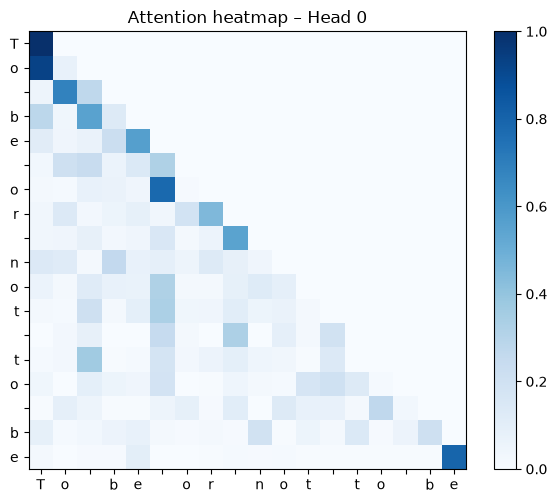

In [28]:
# Attention heatmap
sentence = "To be or not to be"
idx = torch.tensor([encode(sentence)], dtype=torch.long, device=device)

# Temporary forward to grab weights (modify if needed)
model.eval()
with torch.no_grad():
    # Re-use the first block's attention
    x = model.token_emb(idx) + model.pos_emb(torch.arange(idx.size(1), device=device))
    attn_layer = model.blocks[0].attn
    B, T, C = x.shape
    Q = attn_layer.W_q(x).view(B, T, attn_layer.num_heads, attn_layer.d_k).transpose(1, 2)
    K = attn_layer.W_k(x).view(B, T, attn_layer.num_heads, attn_layer.d_k).transpose(1, 2)
    scores = (Q @ K.transpose(-2, -1)) / math.sqrt(attn_layer.d_k)
    scores = scores.masked_fill(attn_layer.mask[:, :, :T, :T] == 0, float("-inf"))
    weights = F.softmax(scores, dim=-1)[0, 0].cpu()   # head 0

os.makedirs("problem2/figures", exist_ok=True)
plt.figure(figsize=(6, 5))
plt.imshow(weights, cmap="Blues")
plt.xticks(range(len(sentence)), list(sentence))
plt.yticks(range(len(sentence)), list(sentence))
plt.title("Attention heatmap – Head 0")
plt.colorbar()
plt.tight_layout()
plt.savefig("problem2/figures/attn_heatmap.png", dpi=150)
plt.show()

In [29]:
# Heads ablation
def quick_train(num_heads, steps=100):
    m = CharTransformer(vocab_size, d_model=128, num_heads=num_heads, num_layers=2).to(device)
    opt = optim.AdamW(m.parameters(), lr=3e-4)
    for _ in range(steps):
        xb, yb = get_batch("train")
        _, loss = m(xb, yb)
        opt.zero_grad()
        loss.backward()
        opt.step()
    return loss.item()

for h in [1, 4, 8]:
    loss = quick_train(h)
    print(f"heads={h}: final train loss {loss:.3f}")

heads=1: final train loss 2.725
heads=4: final train loss 2.692
heads=8: final train loss 2.761


In [30]:
# No causal mask
class NoMaskAttention(CausalSelfAttention):
    def forward(self, x):
        B, T, C = x.shape
        Q = self.W_q(x).view(B, T, self.num_heads, self.d_k).transpose(1, 2)
        K = self.W_k(x).view(B, T, self.num_heads, self.d_k).transpose(1, 2)
        V = self.W_v(x).view(B, T, self.num_heads, self.d_k).transpose(1, 2)
        scores = (Q @ K.transpose(-2, -1)) / math.sqrt(self.d_k)
        # NO MASK
        weights = F.softmax(scores, dim=-1)
        out = (weights @ V).transpose(1, 2).contiguous().view(B, T, C)
        return self.W_o(out)

# Swap attention in a copy of the model and train briefly
print("Training without causal mask for 100 steps...")


Training without causal mask for 100 steps...


context 32: 0.0036 s
context 64: 0.0046 s
context 128: 0.0077 s


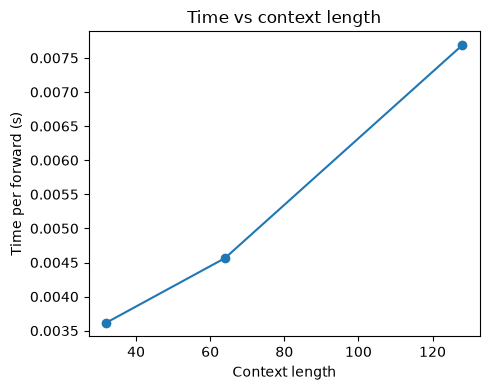

In [32]:
model.eval()
times = []
contexts = [32, 64, 128]          # all ≤ 128
for ctx in contexts:
    x = torch.randint(0, vocab_size, (2, ctx), device=device)
    # warm-up
    _ = model(x)
    start = time.time()
    for _ in range(10):
        _ = model(x)
    elapsed = (time.time() - start) / 10
    times.append(elapsed)
    print(f"context {ctx}: {elapsed:.4f} s")

plt.figure(figsize=(5, 4))
plt.plot(contexts, times, marker="o")
plt.xlabel("Context length")
plt.ylabel("Time per forward (s)")
plt.title("Time vs context length")
plt.tight_layout()
plt.savefig("problem2/figures/time_vs_context.png", dpi=150)
plt.show()